# ASL Citizen: class balance and distribution for the entire vocabulary

**Scope:** all locally available ASL Citizen classes, followed by the current
five-sign subset. Counts are **source video clips**, not frames, augmented
samples or recognition predictions. Exact gloss strings—including numbered
variants—remain separate classes; no relabeling or merging is performed.

This report was prepared on **12 November 2026 (Asia/Tashkent)** from official
local CSV metadata. Actual cached target counts are also checked during
snapshot construction. All tables and figures below have saved outputs.
Videos, checkpoints and a running notebook kernel are not needed to view it.

**Rerunning:** keep `artifacts/asl_citizen_distribution_snapshot.json` beside
this notebook and select the project's Python environment. Analysis uses
NumPy/Matplotlib and normal notebook HTML display. Run All reads the snapshot;
it does not download data or update models. Refresh source data with
`python scripts/build_dataset_distribution_notebook.py` from the repository.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import html
import json
import numpy as np
import matplotlib.pyplot as plt

def find_snapshot():
    for folder in (Path.cwd(), *Path.cwd().parents):
        for relative in ('artifacts/asl_citizen_distribution_snapshot.json',
                         'notebooks/artifacts/asl_citizen_distribution_snapshot.json'):
            path=folder/relative
            if path.is_file():return path
    raise FileNotFoundError('Keep artifacts/asl_citizen_distribution_snapshot.json beside this notebook.')

SNAPSHOT_PATH=find_snapshot()
S=json.loads(SNAPSHOT_PATH.read_text(encoding='utf-8'))
ROWS=S['class_rows']; SPLITS=('train','val','test')
COLORS={'train':'#2563eb','val':'#f59e0b','test':'#16a34a','total':'#7c3aed'}
plt.rcParams.update({'font.size':10,'figure.figsize':(12,5),'axes.spines.top':False,
    'axes.spines.right':False,'figure.constrained_layout.use':True})

def show_table(headers, rows, caption='', height=500):
    # Native Jupyter HTML when rerun; the builder records exactly this markup.
    head=''.join('<th style="position:sticky;top:0;background:#edf2f7;padding:6px">'+html.escape(str(x))+'</th>' for x in headers)
    body=''.join('<tr>'+''.join('<td style="padding:5px;border-bottom:1px solid #ddd">'+html.escape(str(x))+'</td>' for x in row)+'</tr>' for row in rows)
    markup=('<p>'+html.escape(caption)+'</p><div style="max-height:'+str(height)+'px;overflow:auto">'
            '<table style="border-collapse:collapse;font-size:13px;text-align:right"><thead><tr>'+head+
            '</tr></thead><tbody>'+body+'</tbody></table></div>')
    if '_report_emit_html' in globals():
        _report_emit_html(markup)
    else:
        from IPython.display import display,HTML
        display(HTML(markup))

def balance(values):
    a=np.asarray(values,dtype=float);n=len(a);total=a.sum();p=a[a>0]/total
    gini=2*(np.arange(1,n+1)*np.sort(a)).sum()/(n*total)-(n+1)/n
    return {'min':int(a.min()),'median':float(np.median(a)),'mean':float(a.mean()),'max':int(a.max()),
            'p10':float(np.quantile(a,.1)),'p90':float(np.quantile(a,.9)),
            'cv':float(a.std()/a.mean()),'gini':float(max(0,gini)),
            'normalized_entropy':float(-(p*np.log(p)).sum()/np.log(n)) if n>1 else 1.,
            'max_min':float(a.max()/a.min()) if a.min()>0 else None}

print('Dataset:',S['dataset'])
print('Snapshot date:',S['report_date_local'],S['timezone'])
print(f"{len(ROWS):,} distinct gloss classes; {sum(r['total'] for r in ROWS):,} source video clips")
print('Read-only analysis: no training, extraction, model evaluation or camera access.')

Dataset: Microsoft ASL Citizen
Snapshot date: 2026-11-12 Asia/Tashkent
2,731 distinct gloss classes; 83,399 source video clips
Read-only analysis: no training, extraction, model evaluation or camera access.


## 1. What is present, and what was verified?

The official train/validation/test partitions are preserved. Signer sets are
disjoint: a person in one partition does not appear in another. Clip counts
are not expected to form an 80/20 split. File existence, video decoding and
landmark accuracy are **not** audited by this notebook.

In [2]:
grand=sum(r['total'] for r in ROWS)
show_table(['Split','Clips','Share of dataset','Classes present','Signers'],
    [[s,f"{S['split_summary'][s]['clips']:,}",f"{100*S['split_summary'][s]['clips']/grand:.2f}%",
      S['split_summary'][s]['classes'],S['split_summary'][s]['signers']] for s in SPLITS],
    'Official metadata totals')
print('Unique video entries:',S['integrity']['unique_video_count'])
print('Duplicate video entries:',S['integrity']['duplicate_videos'])
print('Participant-disjoint:',S['integrity']['participant_disjoint'])
print('Prepared feature-cache count check:',S['prepared_cache_check']['status'])
print('Five-sign subset count check:',S['five_sign_cache_check']['status'])
show_table(['Source metadata / cached labels','SHA256'],list(S['source_sha256'].items()),'Input provenance',240)

Split,Clips,Share of dataset,Classes present,Signers
train,"40,154",48.15%,2731,35
val,"10,304",12.36%,2731,6
test,"32,941",39.50%,2731,11


Unique video entries: 83399
Duplicate video entries: 0
Participant-disjoint: True
Prepared feature-cache count check: verified
Five-sign subset count check: verified


Source metadata / cached labels,SHA256
data/asl_citizen/ASL_Citizen/splits/train.csv,87a105649b98ea577182ebfce49d59fe9ca834a2489384f6fe7bc03f14966329
data/asl_citizen/ASL_Citizen/splits/val.csv,6ac78c9d551dfcc81d225a5279d7637c2891a4490851234be6e4674666e21366
data/asl_citizen/ASL_Citizen/splits/test.csv,b1dee8f81204895ca1760f6bd582eec84cf390b9c97c4387e49b9cc6b906b21e
data/training/asl-gru-128-v1/train-targets.npy,469f34bd4062a234846d2c64226b6618e64d6bd88c996dcb83953c9249867edc
data/training/asl-gru-128-v1/val-targets.npy,133797ad95788ba27b6156167958cfff8042be81043d9ad4802e29be3817f180
data/training/asl-gru-128-v1/test-targets.npy,f6453f0aa61943103c399d83cd902b0c4638febc5b6bc34d3da528322e2b2482


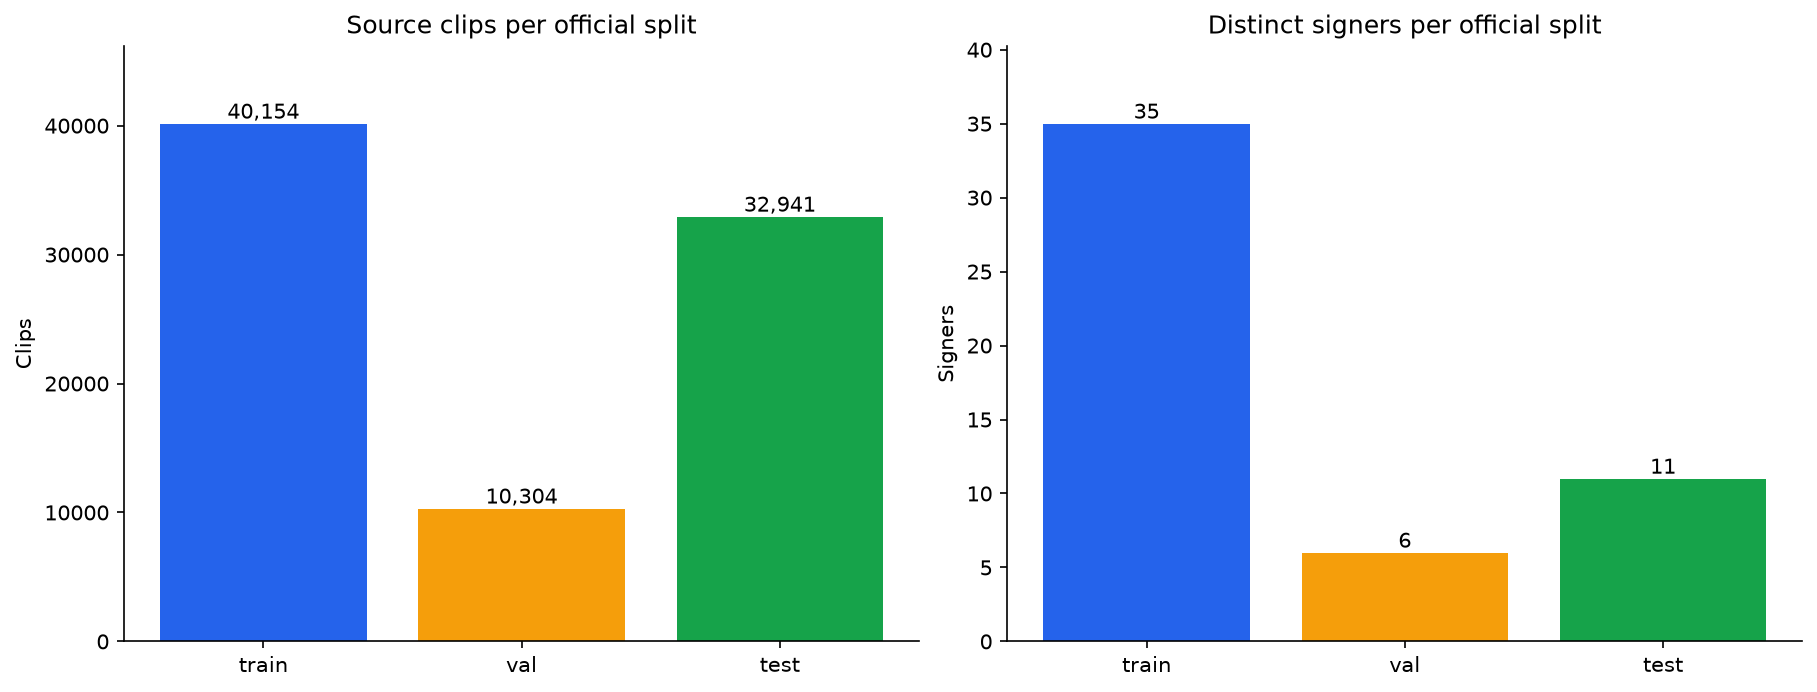

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,key,title in [(axes[0],'clips','Source clips per official split'),(axes[1],'signers','Distinct signers per official split')]:
    values=[S['split_summary'][s][key] for s in SPLITS]
    bars=ax.bar(SPLITS,values,color=[COLORS[s] for s in SPLITS])
    for b,v in zip(bars,values):ax.text(b.get_x()+b.get_width()/2,v,f'{v:,}',ha='center',va='bottom')
    ax.set_ylim(0,max(values)*1.15);ax.set_title(title);ax.set_ylabel(key.capitalize())
plt.show()

## 2. How balanced are the classes?

**Mean/median** describe examples per class, not performance. **CV** is the
population standard deviation divided by the mean (lower means less relative
count variation). **Gini** is 0 for equal counts and rises with concentration.
**Normalized entropy** is 100% for equal counts. A largest/smallest ratio can
be driven by a few outliers, so examine the full distributions as well.
Zero-count classes remain included; a ratio involving a zero is undefined.

In [4]:
summaries={s:balance([r[s] for r in ROWS]) for s in (*SPLITS,'total')}
show_table(['Partition','Min','P10','Median','Mean','P90','Max','Max/min','CV','Gini','Normalized entropy'],
    [[s,v['min'],f"{v['p10']:.1f}",f"{v['median']:.1f}",f"{v['mean']:.2f}",f"{v['p90']:.1f}",v['max'],
      f"{v['max_min']:.2f}" if v['max_min'] is not None else 'undefined',f"{v['cv']:.3f}",f"{v['gini']:.4f}",
      f"{100*v['normalized_entropy']:.3f}%"] for s,v in summaries.items()])
all_counts=np.asarray([r['total'] for r in ROWS]);train_counts=np.asarray([r['train'] for r in ROWS])
print(f"Classes with 30 or 31 total clips: {np.isin(all_counts,[30,31]).sum():,}/{len(ROWS):,}")
print(f"Training examples per class: median {np.median(train_counts):.0f}; range {train_counts.min()}–{train_counts.max()}")
print('Frequency balance does not establish that classes are equally easy to recognize.')

Partition,Min,P10,Median,Mean,P90,Max,Max/min,CV,Gini,Normalized entropy
train,9,13.0,15.0,14.70,16.0,24,2.67,0.089,0.0460,99.950%
val,2,3.0,4.0,3.77,5.0,7,3.50,0.188,0.0973,99.780%
test,7,11.0,12.0,12.06,13.0,20,2.86,0.099,0.0501,99.938%
total,21,30.0,31.0,30.54,31.0,45,2.14,0.057,0.0216,99.980%


Classes with 30 or 31 total clips: 2,239/2,731
Training examples per class: median 15; range 9–24
Frequency balance does not establish that classes are equally easy to recognize.


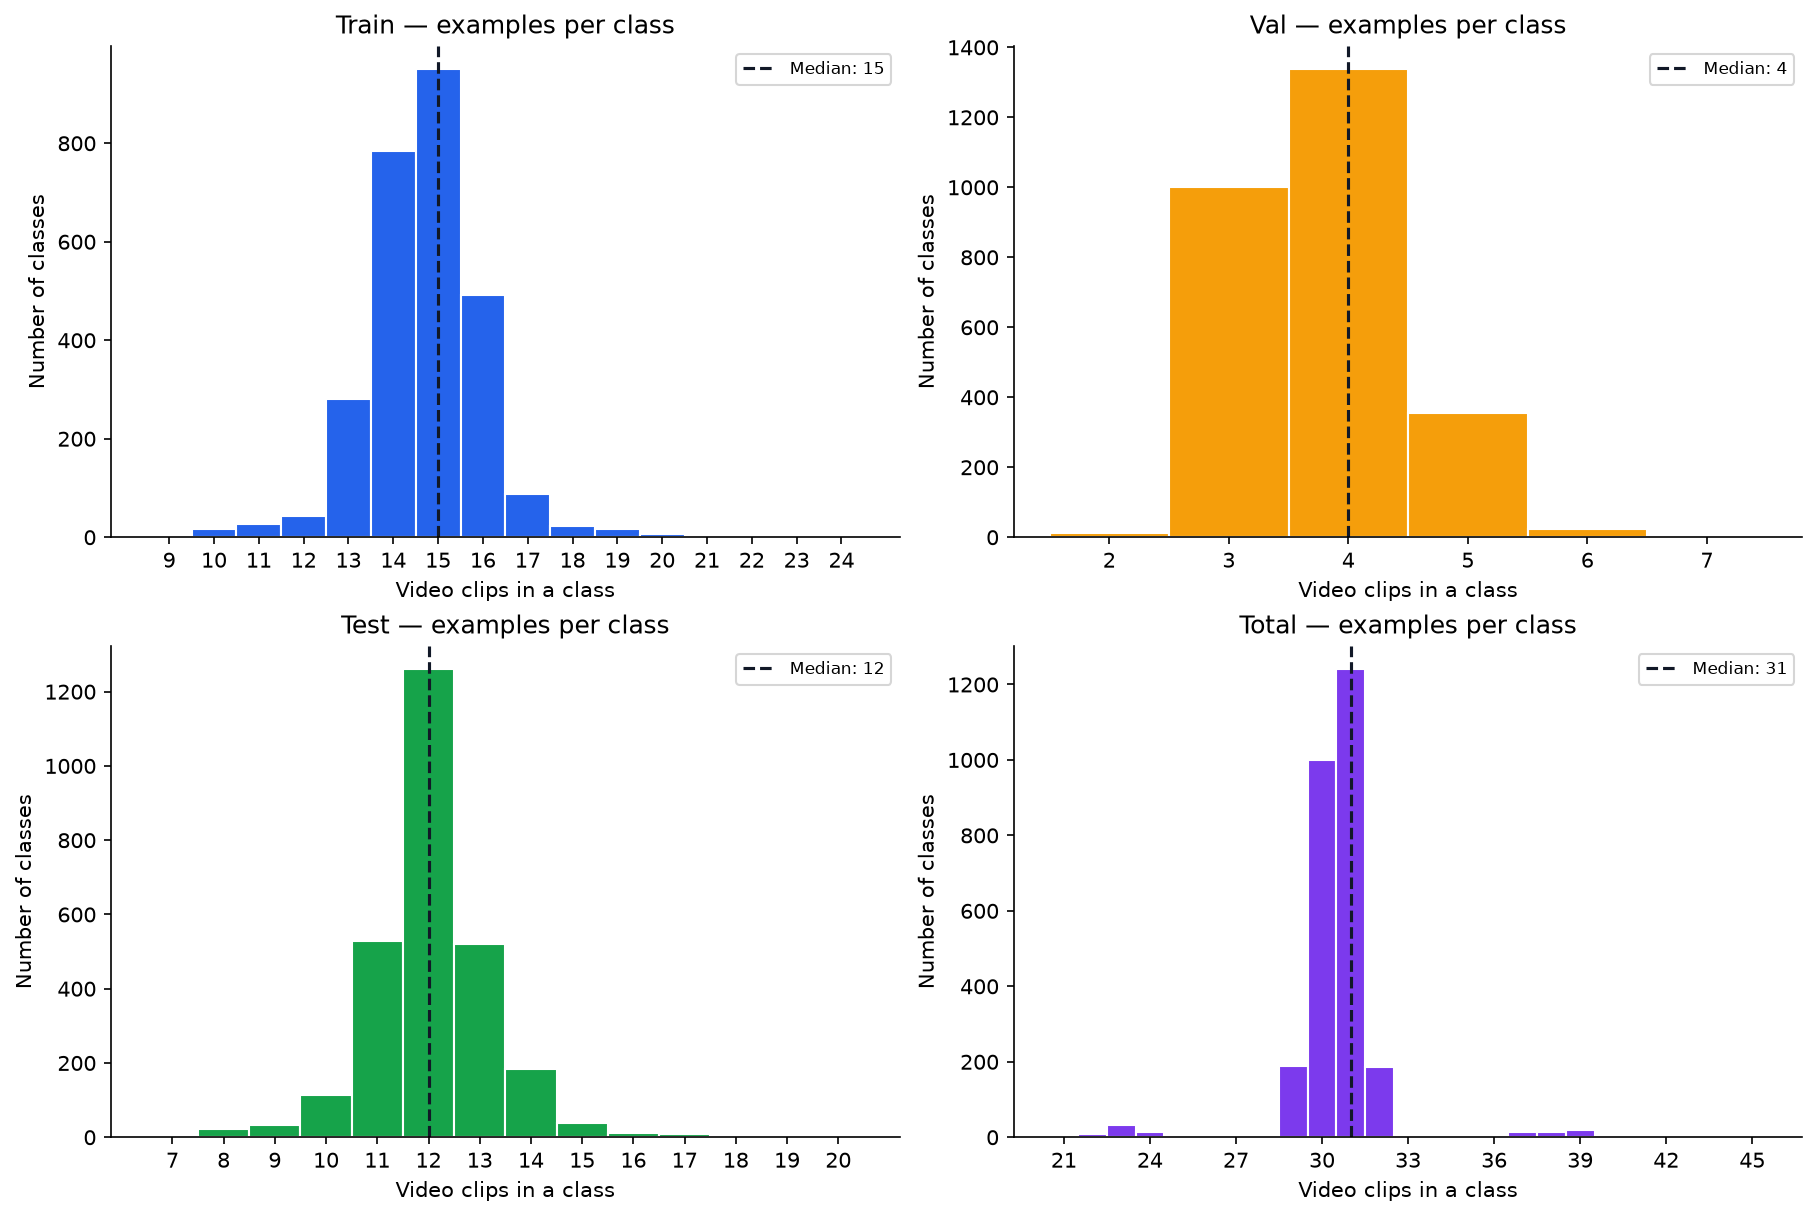

In [5]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,s in zip(axes.flat,(*SPLITS,'total')):
    values=np.asarray([r[s] for r in ROWS]);low,high=int(values.min()),int(values.max())
    ax.hist(values,bins=np.arange(low-.5,high+1.5),color=COLORS[s],edgecolor='white')
    ax.axvline(np.median(values),color='#111827',linestyle='--',label=f'Median: {np.median(values):g}')
    ax.set_title(s.capitalize()+' — examples per class');ax.set_xlabel('Video clips in a class')
    ax.set_ylabel('Number of classes');ax.set_xticks(np.arange(low,high+1,max(1,(high-low)//8)))
    ax.legend(fontsize=8)
plt.show()

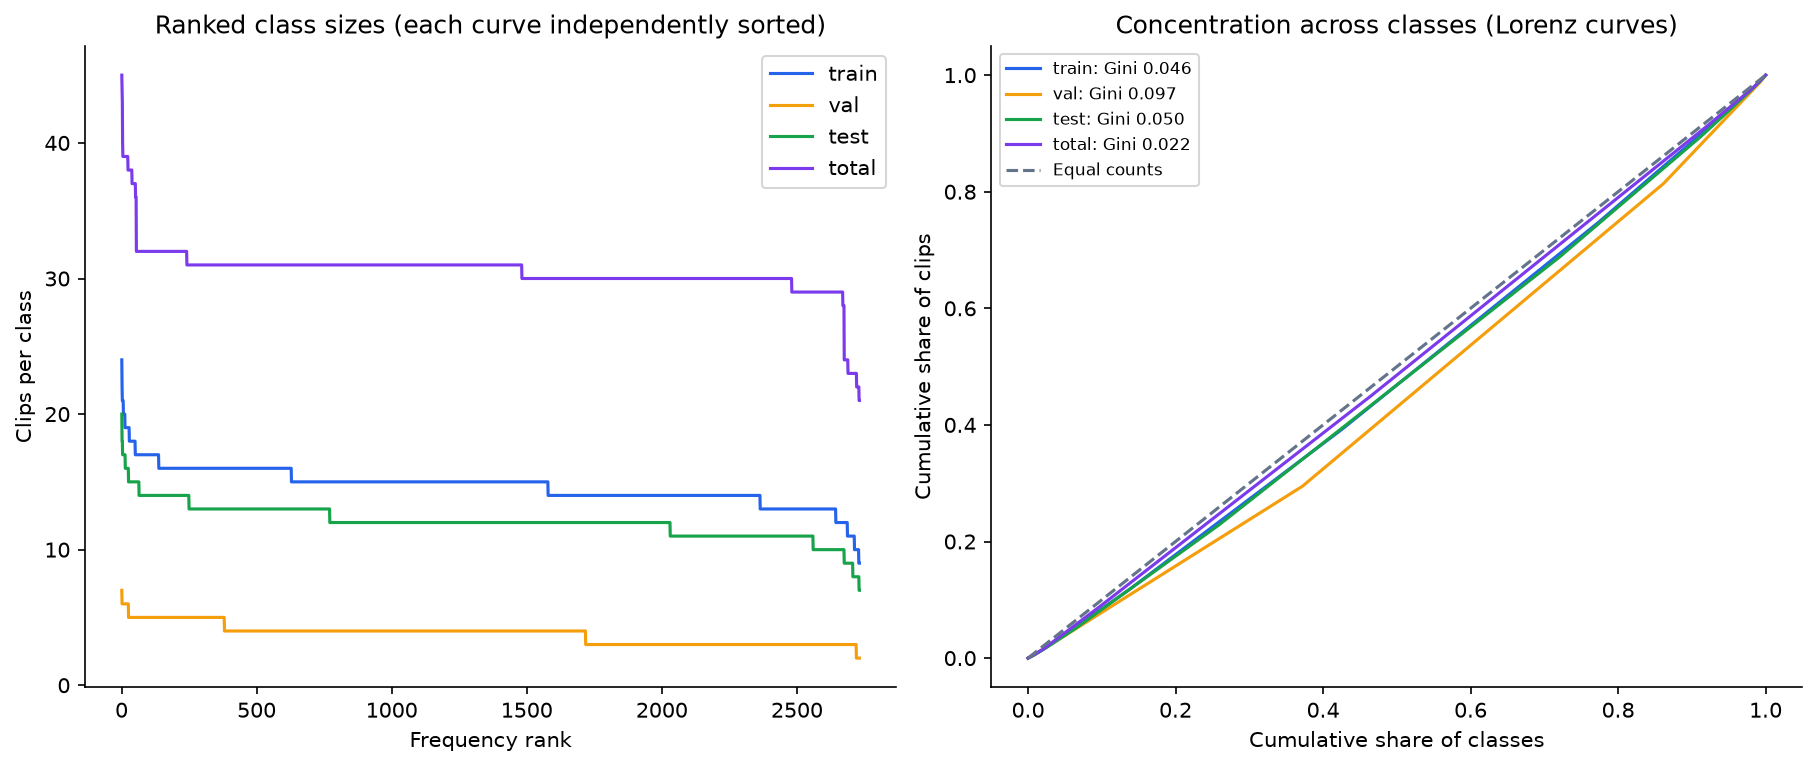

Total clips in a class,Number of classes,Share of vocabulary
21,2,0.07%
22,9,0.33%
23,32,1.17%
24,14,0.51%
28,5,0.18%
29,189,6.92%
30,999,36.58%
31,1240,45.40%
32,187,6.85%
36,3,0.11%


In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for s in (*SPLITS,'total'):
    values=np.sort([r[s] for r in ROWS])
    axes[0].plot(np.arange(1,len(values)+1),values[::-1],label=s,color=COLORS[s])
    cumulative=np.r_[0,np.cumsum(values)/sum(values)]
    axes[1].plot(np.linspace(0,1,len(values)+1),cumulative,label=f"{s}: Gini {summaries[s]['gini']:.3f}",color=COLORS[s])
axes[0].set(title='Ranked class sizes (each curve independently sorted)',xlabel='Frequency rank',ylabel='Clips per class')
axes[0].legend();axes[1].plot([0,1],[0,1],'--',color='#64748b',label='Equal counts')
axes[1].set(title='Concentration across classes (Lorenz curves)',xlabel='Cumulative share of classes',ylabel='Cumulative share of clips')
axes[1].legend(fontsize=8);plt.show()
frequency=Counter(r['total'] for r in ROWS)
show_table(['Total clips in a class','Number of classes','Share of vocabulary'],
    [[n,frequency[n],f'{100*frequency[n]/len(ROWS):.2f}%'] for n in sorted(frequency)],
    'Exact distribution of total class sizes',350)

## 3. Which classes have the fewest or most examples?

Rankings below use **total source clips**, with alphabetical tie-breaking.
Numbered gloss variants are intentionally not merged. A rare class label
is not automatically a label error or a different word meaning.

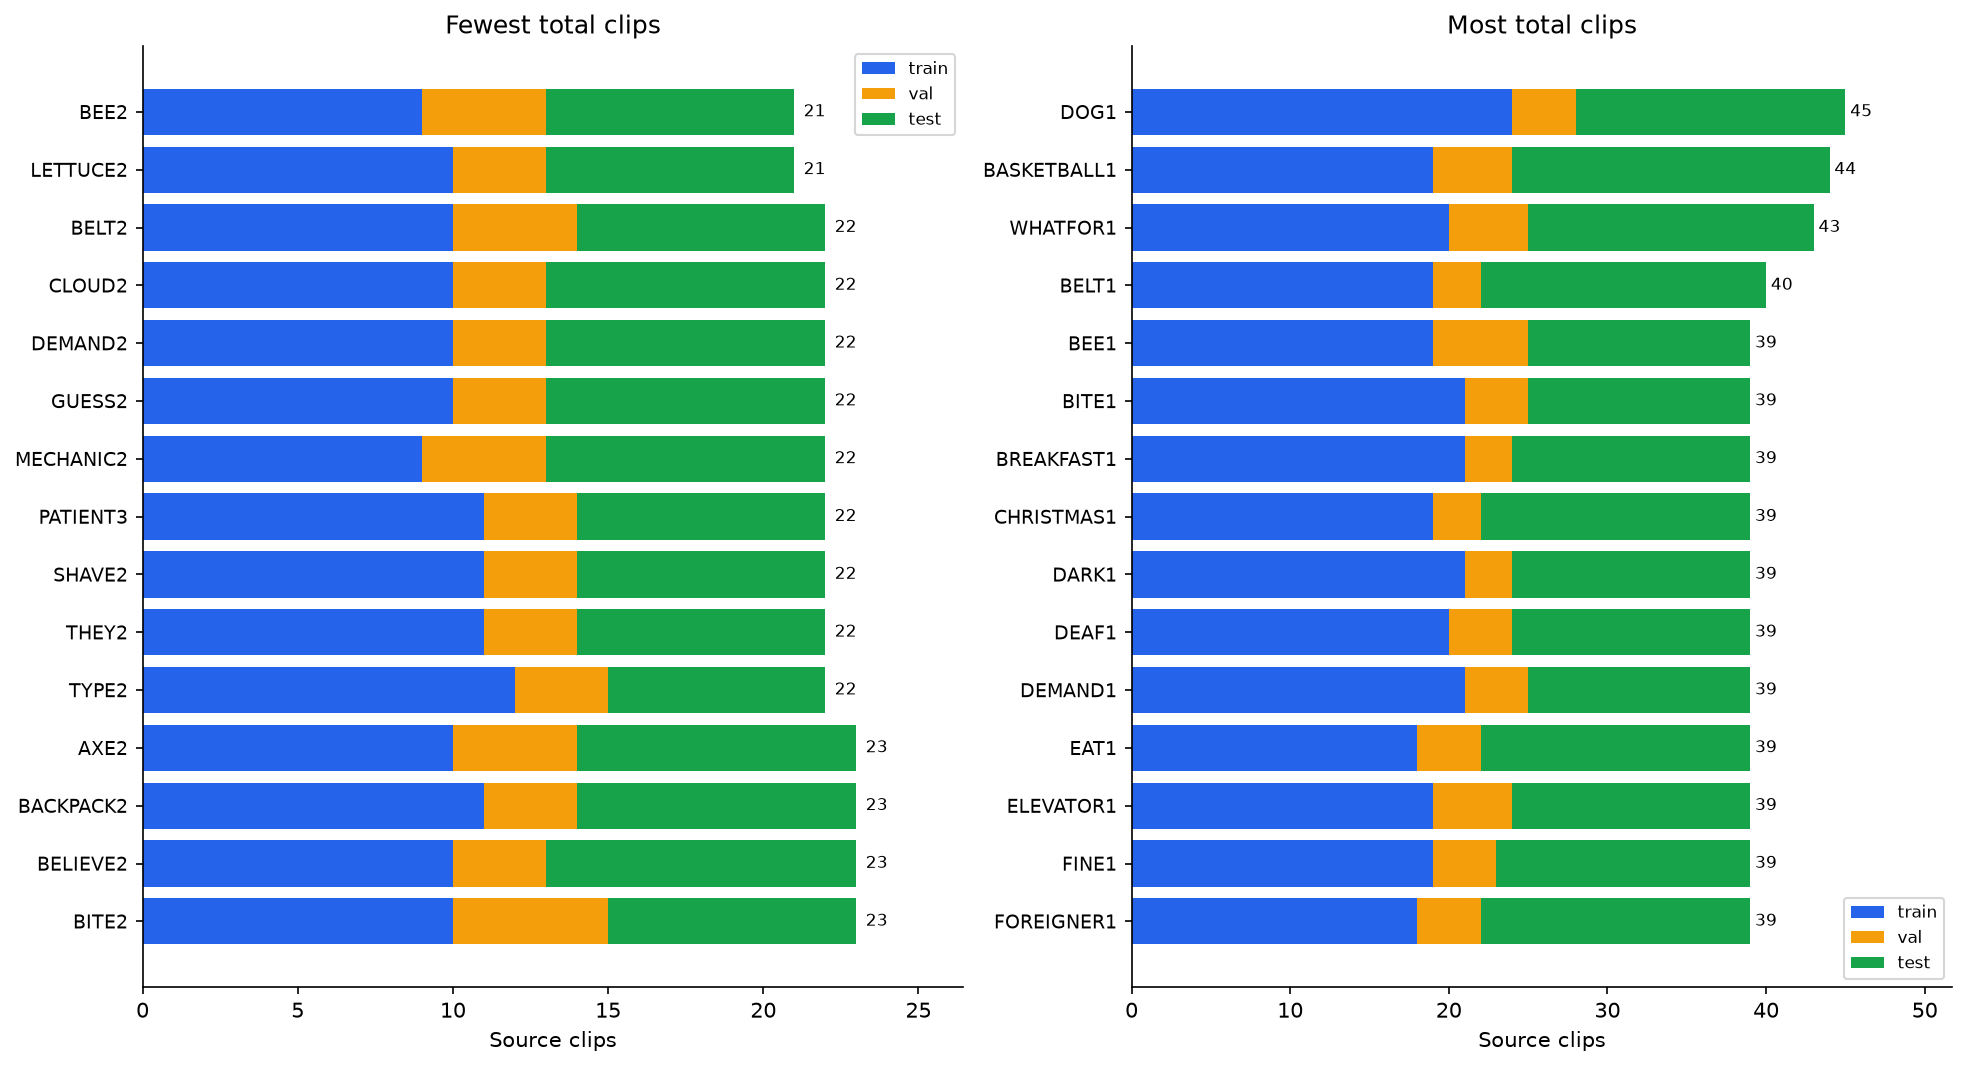

Class,Train,Val,Test,Total
BEE2,9,4,8,21
LETTUCE2,10,3,8,21
BELT2,10,4,8,22
CLOUD2,10,3,9,22
DEMAND2,10,3,9,22
GUESS2,10,3,9,22
MECHANIC2,9,4,9,22
PATIENT3,11,3,8,22
SHAVE2,11,3,8,22
THEY2,11,3,8,22


Class,Train,Val,Test,Total
DOG1,24,4,17,45
BASKETBALL1,19,5,20,44
WHATFOR1,20,5,18,43
BELT1,19,3,18,40
BEE1,19,6,14,39
BITE1,21,4,14,39
BREAKFAST1,21,3,15,39
CHRISTMAS1,19,3,17,39
DARK1,21,3,15,39
DEAF1,20,4,15,39


In [7]:
smallest=sorted(ROWS,key=lambda r:(r['total'],r['gloss']))[:15]
largest=sorted(ROWS,key=lambda r:(-r['total'],r['gloss']))[:15]
fig,axes=plt.subplots(1,2,figsize=(13,7))
for ax,rows,title in [(axes[0],smallest,'Fewest total clips'),(axes[1],largest,'Most total clips')]:
    y=np.arange(len(rows));left=np.zeros(len(rows))
    for s in SPLITS:
        values=np.asarray([r[s] for r in rows]);ax.barh(y,values,left=left,color=COLORS[s],label=s);left+=values
    for i,total in enumerate(left):ax.text(total+.3,i,str(int(total)),va='center',fontsize=8)
    ax.set_yticks(y,[r['gloss'] for r in rows],fontsize=9);ax.invert_yaxis()
    ax.set_xlim(0,max(left)*1.15);ax.set_xlabel('Source clips');ax.set_title(title);ax.legend(fontsize=8)
plt.show()
show_table(['Class','Train','Val','Test','Total'],
    [[r['gloss'],r['train'],r['val'],r['test'],r['total']] for r in smallest], '15 smallest classes')
show_table(['Class','Train','Val','Test','Total'],
    [[r['gloss'],r['train'],r['val'],r['test'],r['total']] for r in largest], '15 largest classes')

## 4. Split coverage and signer distribution

Total balance can hide different allocations to train/validation/test. Small
per-class validation counts also make per-class evaluation coarse. These
counts do not justify moving evaluation signers into training. Signer IDs
below are the public anonymized participant codes, not personal identities.

Partition,Classes present,Classes missing,Min per class,Median per class,Max per class
train,2731,0,9,15,24
val,2731,0,2,4,7
test,2731,0,7,12,20


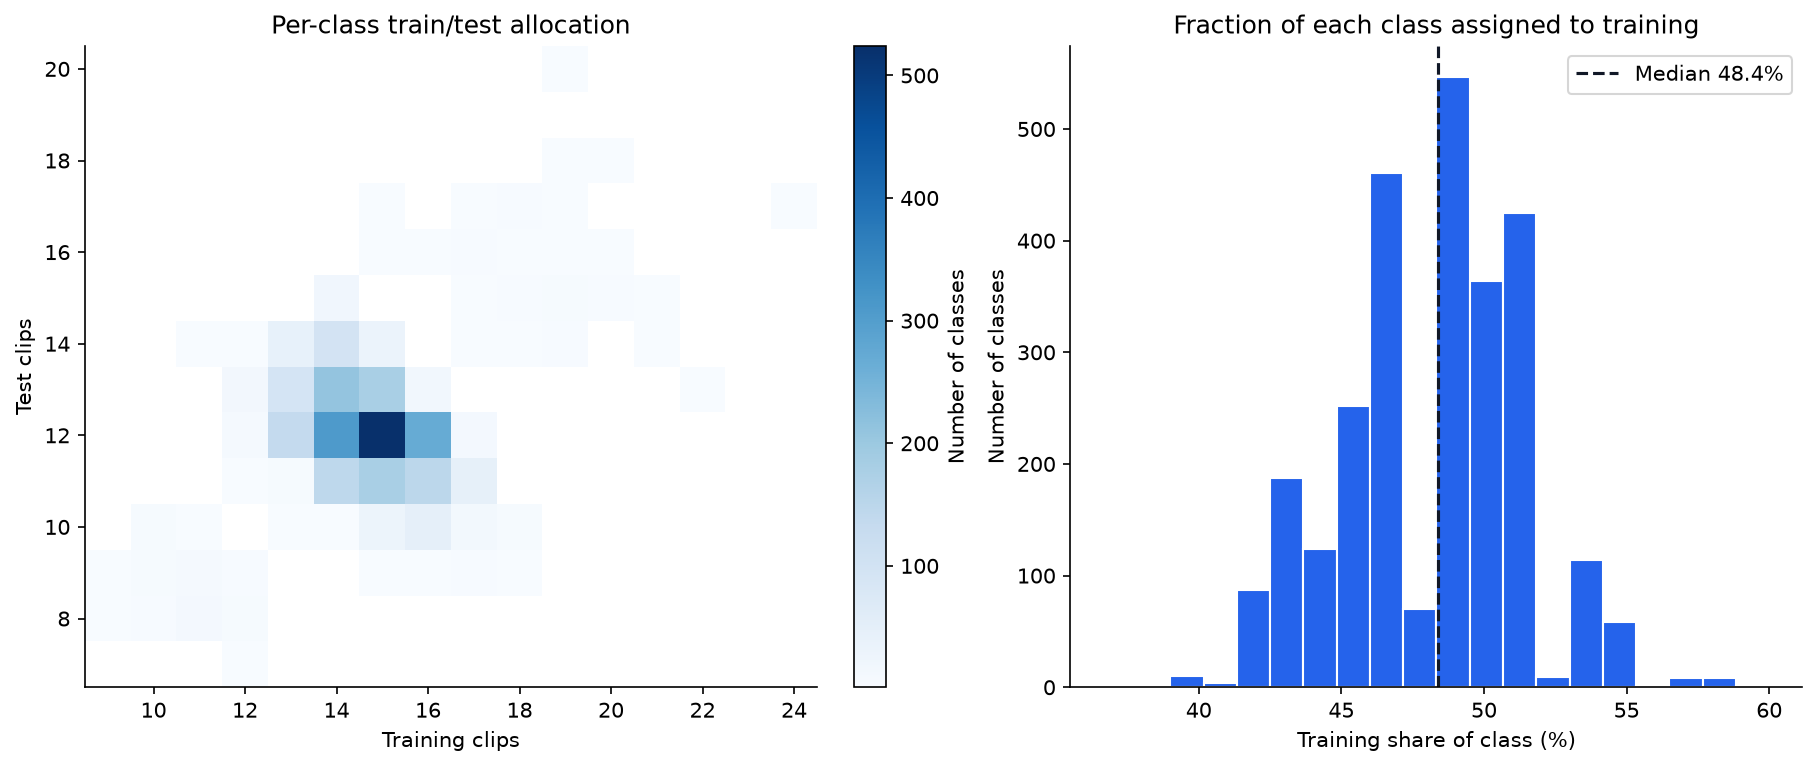

In [8]:
show_table(['Partition','Classes present','Classes missing','Min per class','Median per class','Max per class'],
    [[s,sum(r[s]>0 for r in ROWS),sum(r[s]==0 for r in ROWS),min(r[s] for r in ROWS),
      f'{np.median([r[s] for r in ROWS]):.0f}',max(r[s] for r in ROWS)] for s in SPLITS])
train=np.asarray([r['train'] for r in ROWS]);test=np.asarray([r['test'] for r in ROWS])
fig,axes=plt.subplots(1,2,figsize=(12,5))
h=axes[0].hist2d(train,test,bins=[np.arange(train.min()-.5,train.max()+1.5),np.arange(test.min()-.5,test.max()+1.5)],cmap='Blues',cmin=1)
fig.colorbar(h[3],ax=axes[0],label='Number of classes')
axes[0].set(title='Per-class train/test allocation',xlabel='Training clips',ylabel='Test clips')
fractions=np.asarray([100*r['train']/r['total'] for r in ROWS])
axes[1].hist(fractions,bins=20,color=COLORS['train'],edgecolor='white')
axes[1].axvline(np.median(fractions),color='#111827',linestyle='--',label=f'Median {np.median(fractions):.1f}%')
axes[1].set(title='Fraction of each class assigned to training',xlabel='Training share of class (%)',ylabel='Number of classes');axes[1].legend()
plt.show()

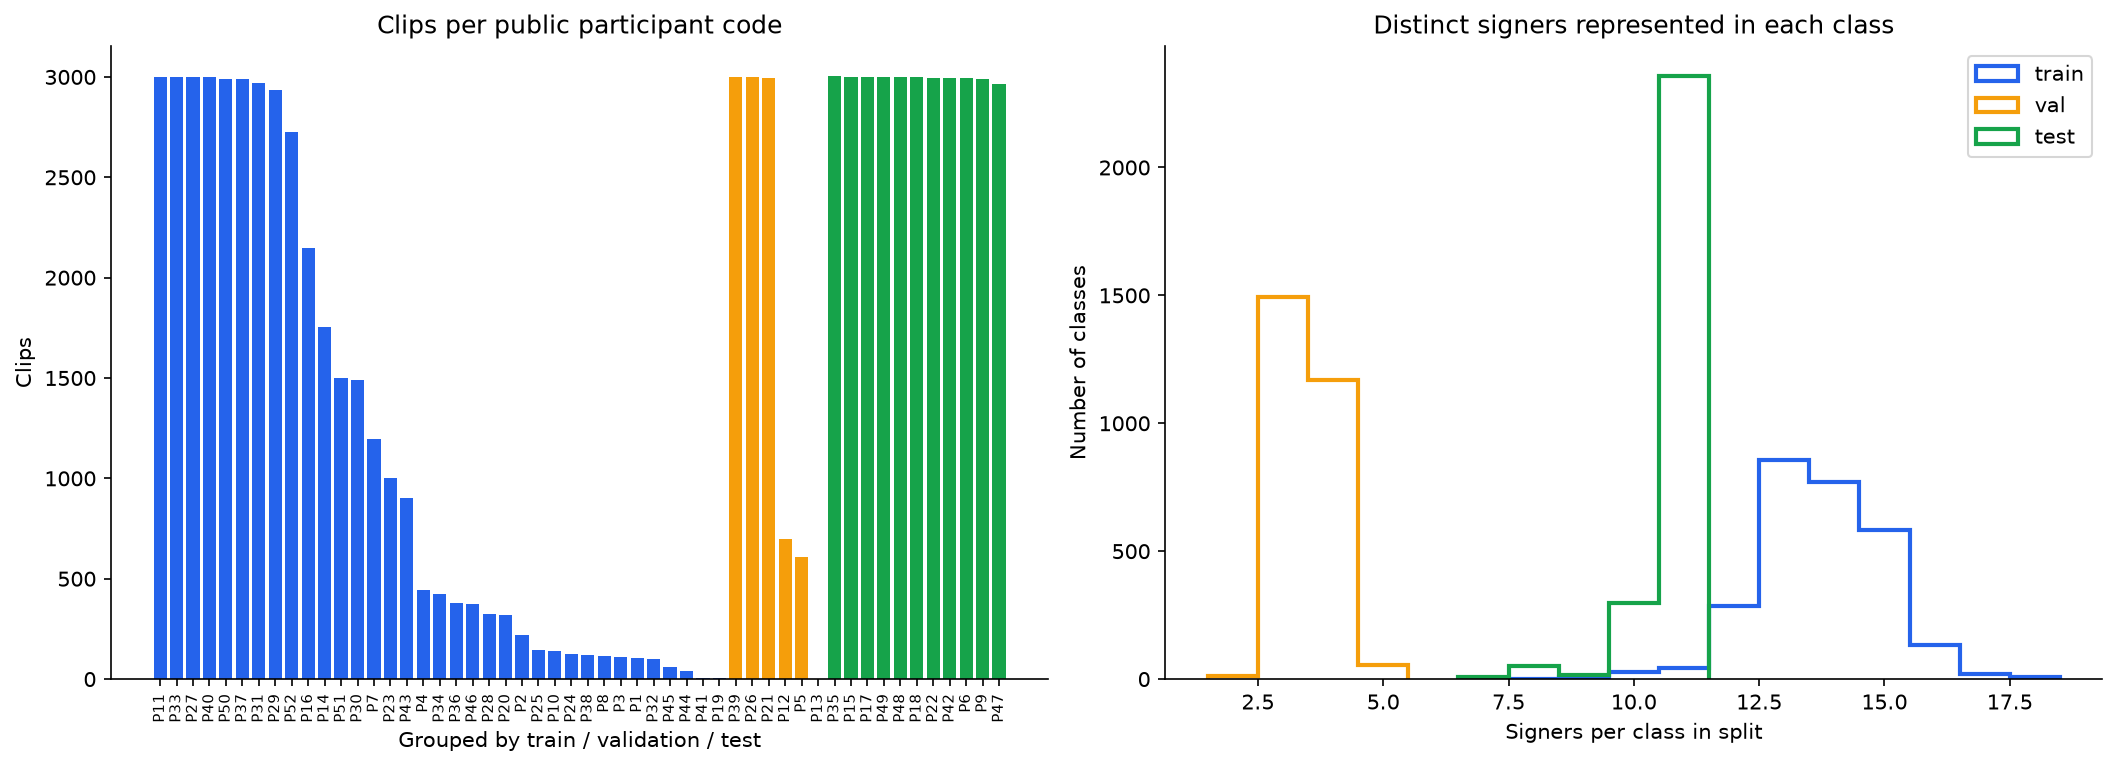

Split,Min signers/class,Median signers/class,Max signers/class
train,8,14,18
val,2,3,5
test,7,11,11


In [9]:
signer_rows=sorted(S['signer_rows'],key=lambda r:(SPLITS.index(r['split']),-r['clips'],r['participant_id']))
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].bar(np.arange(len(signer_rows)),[r['clips'] for r in signer_rows],color=[COLORS[r['split']] for r in signer_rows])
axes[0].set_xticks(np.arange(len(signer_rows)),[r['participant_id'] for r in signer_rows],rotation=90,fontsize=7)
axes[0].set(title='Clips per public participant code',ylabel='Clips',xlabel='Grouped by train / validation / test')
for s in SPLITS:
    values=[r[s+'_signers'] for r in ROWS]
    axes[1].hist(values,bins=np.arange(min(values)-.5,max(values)+1.5),histtype='step',linewidth=2,label=s,color=COLORS[s])
axes[1].set(title='Distinct signers represented in each class',xlabel='Signers per class in split',ylabel='Number of classes');axes[1].legend()
plt.show()
show_table(['Split','Min signers/class','Median signers/class','Max signers/class'],
    [[s,min(r[s+'_signers'] for r in ROWS),f"{np.median([r[s+'_signers'] for r in ROWS]):.0f}",max(r[s+'_signers'] for r in ROWS)] for s in SPLITS])

## 5. Where the current five-sign experiment fits

The current five-sign subset keeps **all available examples** of its glosses
in their original splits. It was not capped at 14–16 training clips by a
sampling rule. Online augmentation creates variations of those source clips;
it does not add new recorded examples or new signers.

Sign,Train,Val,Test,Total,Training share within five signs
HELLO,14,4,14,32,18.7%
NO,16,3,11,30,21.3%
PLEASE,14,4,13,31,18.7%
THANKYOU,16,3,12,31,21.3%
YES,15,5,10,30,20.0%


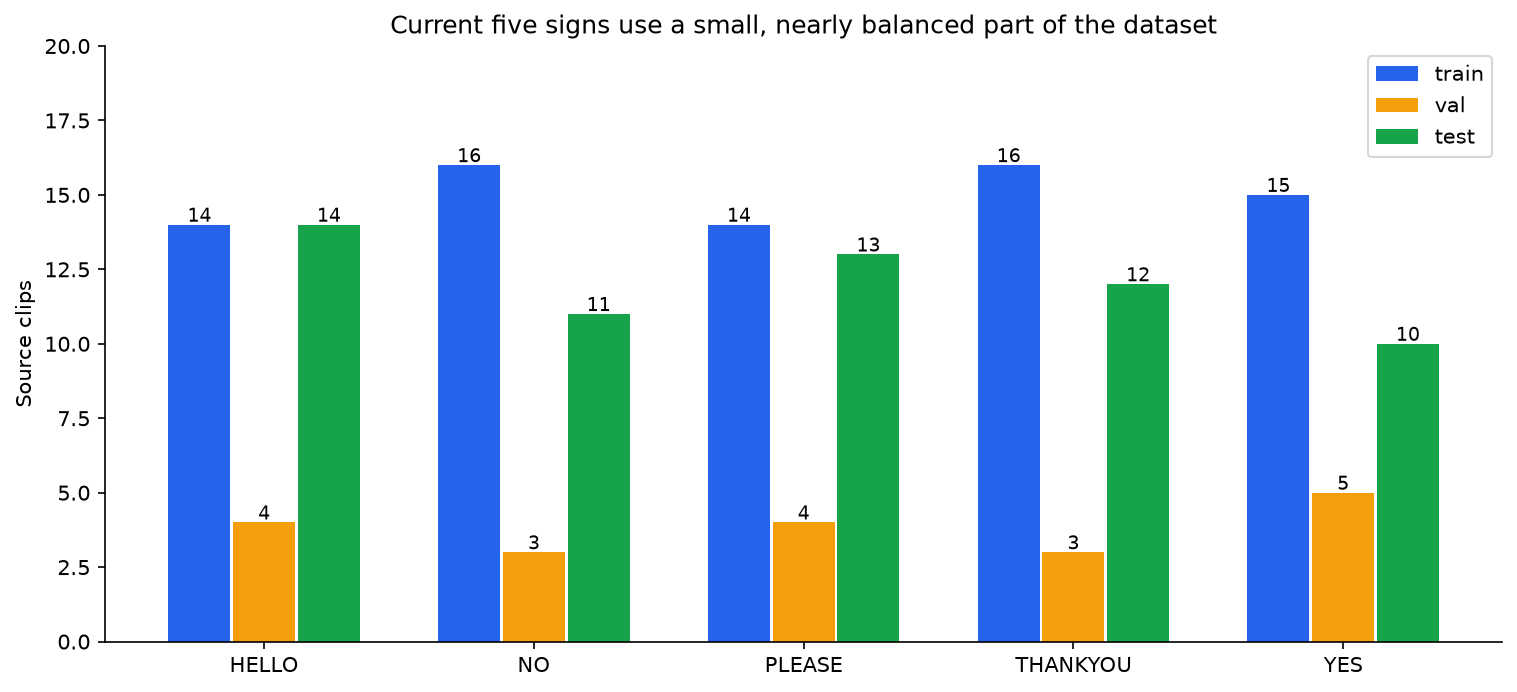

In [10]:
focus=S['five_sign_rows']
if focus:
    show_table(['Sign','Train','Val','Test','Total','Training share within five signs'],
        [[r['gloss'],r['train'],r['val'],r['test'],r['total'],f"{100*r['train']/sum(x['train'] for x in focus):.1f}%"] for r in focus])
    fig,ax=plt.subplots(figsize=(10,4.5));pos=np.arange(len(focus))
    for offset,s in [(-.24,'train'),(0,'val'),(.24,'test')]:
        values=[r[s] for r in focus];bars=ax.bar(pos+offset,values,.23,label=s,color=COLORS[s])
        for b,v in zip(bars,values):ax.text(b.get_x()+b.get_width()/2,v+.1,str(v),ha='center',fontsize=9)
    ax.set_xticks(pos,[r['gloss'] for r in focus]);ax.set_ylim(0,max(r[s] for r in focus for s in SPLITS)*1.25)
    ax.set_ylabel('Source clips');ax.set_title('Current five signs use a small, nearly balanced part of the dataset');ax.legend();plt.show()
else:print('No current five-sign glosses in this snapshot.')

## 6. Full class table: every class is included

The saved output below contains every class, in a scrollable table. With a
kernel, edit **SEARCH**, **SORT_BY**, **DESCENDING** or **LIMIT** and rerun
this cell to inspect a subset. `LIMIT=None` keeps all matching classes.
Sort columns: `gloss`, `train`, `val`, `test`, `total`, `total_signers`.
The training share column uses the **entire training split** as denominator.

In [11]:
SEARCH = ''            # Example: 'HELLO' (case-insensitive substring).
SORT_BY = 'total'      # Counts ascending by default.
DESCENDING = False
LIMIT = None          # Keep None to display ALL matching classes.
assert SORT_BY in ('gloss','train','val','test','total','total_signers')
selected=[r for r in ROWS if SEARCH.upper() in r['gloss'].upper()]
selected=sorted(selected,key=lambda r:(r[SORT_BY],r['gloss']),reverse=DESCENDING)
if LIMIT is not None:selected=selected[:LIMIT]
show_table(['Gloss class','Train','Validation','Test','Total','Share of all training clips','Distinct signers, all splits'],
    [[r['gloss'],r['train'],r['val'],r['test'],r['total'],f"{100*r['train']/S['split_summary']['train']['clips']:.4f}%",r['total_signers']] for r in selected],
    f'{len(selected):,} displayed classes / {len(ROWS):,} total vocabulary classes',height=620)
assert LIMIT is not None or len(selected)==sum(SEARCH.upper() in r['gloss'].upper() for r in ROWS)

Gloss class,Train,Validation,Test,Total,Share of all training clips,"Distinct signers, all splits"
BEE2,9,4,8,21,0.0224%,19
LETTUCE2,10,3,8,21,0.0249%,21
BELT2,10,4,8,22,0.0249%,20
CLOUD2,10,3,9,22,0.0249%,21
DEMAND2,10,3,9,22,0.0249%,21
GUESS2,10,3,9,22,0.0249%,21
MECHANIC2,9,4,9,22,0.0224%,19
PATIENT3,11,3,8,22,0.0274%,21
SHAVE2,11,3,8,22,0.0274%,22
THEY2,11,3,8,22,0.0274%,20


## 7. Interpretation and limits

- The full vocabulary is close to balanced by clip frequency; most classes
  have about 30–31 source clips in total. A few numbered variants form the
  lowest/highest-count tails. Consult the computed statistics above.
- The training allocation is much smaller per class than the whole dataset
  size suggests: the median is about 15 training clips per class. A large
  vocabulary and 83k total clips do not mean thousands of examples per sign.
- Clip balance alone does not establish sufficient variation, accurate
  landmarks, correct labels, semantic uniqueness or good webcam performance.
- This is metadata analysis, including evaluation-label frequencies. No
  evaluation predictions, model selection or training were performed. The
  official signer-disjoint split remains intact.
- The snapshot is a dated report, not a live view of future dataset edits.
  Its source SHA256 values identify the metadata and cached target arrays.

Sources: local official `data/asl_citizen/ASL_Citizen/splits/*.csv`, full
prepared-cache target counts, and the current five-sign subset manifest.
Dataset attribution: [Microsoft ASL Citizen](https://www.microsoft.com/en-us/research/project/asl-citizen/).
The planned Slovo/RSL dataset is outside this ASL-only report.